In [ ]:
# Import các thư viện cần thiết
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

# Scikit-learn cho việc tiền xử lý và chia dữ liệu
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Cài đặt cho đồ thị đẹp hơn
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

# 1. Import dữ liệu

In [ ]:
# Đọc file CSV
# df = pd.read_csv('heart.csv')
url = 'https://drive.google.com/file/d/1a6_k0rWYFmcQCliqxMFE9zPAwebNxCmw/view?usp=sharing'
url ='https://drive.google.com/uc?id=' + url.split('/')[-2]
df = pd.read_csv(url)
df

# Hiển thị 5 dòng đầu tiên
print("5 dòng dữ liệu đầu tiên:")
print(df.head())
print("\n" + "="*50 + "\n")

# Kiểm tra thông tin tổng quan và kiểu dữ liệu
print("Thông tin tổng quan của dữ liệu:")
df.info()
print("\n" + "="*50 + "\n")

# Xem thống kê mô tả
print("Thống kê mô tả các thuộc tính:")
print(df.describe())

5 dòng dữ liệu đầu tiên:
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   3       145   233    1        0      150      0      2.3      0   
1   37    1   2       130   250    0        1      187      0      3.5      0   
2   41    0   1       130   204    0        0      172      0      1.4      2   
3   56    1   1       120   236    0        1      178      0      0.8      2   
4   57    0   0       120   354    0        1      163      1      0.6      2   

   ca  thal  target  
0   0     1       1  
1   0     2       1  
2   0     2       1  
3   0     2       1  
4   0     2       1  


Thông tin tổng quan của dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 no

# 2. Tiền xử lý dữ liệu


In [ ]:
# 1. Tách X và y
X = df.drop('target', axis=1)
y = df['target']

# 2. Chia dữ liệu thành tập train và test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Chuẩn hóa dữ liệu
# Lưu ý: Chỉ 'fit' trên tập train và 'transform' cho cả train và test
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Thêm cột bias (giá trị 1) vào đầu ma trận X
X_train_final = np.c_[np.ones(X_train_scaled.shape[0]), X_train_scaled]
X_test_final = np.c_[np.ones(X_test_scaled.shape[0]), X_test_scaled]

# Chuyển y thành vector cột để tính toán dễ dàng
y_train = y_train.values.reshape(-1, 1)
y_test = y_test.values.reshape(-1, 1)


print("Kích thước tập huấn luyện (X, y):", X_train_final.shape, y_train.shape)
print("Kích thước tập kiểm tra (X, y):", X_test_final.shape, y_test.shape)

Kích thước tập huấn luyện (X, y): (242, 14) (242, 1)
Kích thước tập kiểm tra (X, y): (61, 14) (61, 1)


# 3. Xây dựng các thành phần của Hồi quy Logistic

In [ ]:
def sigmoid(z):
    """Tính toán hàm sigmoid."""
    return 1 / (1 + np.exp(-z))

def compute_loss(X, y, w):
    """Tính toán hàm mất mát Binary Cross-Entropy."""
    N = len(y)
    p = sigmoid(X @ w)
    # Thêm một giá trị rất nhỏ để tránh lỗi log(0)
    epsilon = 1e-9
    loss = - (1/N) * np.sum(y * np.log(p + epsilon) + (1 - y) * np.log(1 - p + epsilon))
    return loss

# 4. Triển khai các thuật toán tối ưu

In [ ]:
def gradient_descent_method(X, y, learning_rate, iterations):
    """Triển khai thuật toán Gradient Descent."""
    N, d = X.shape
    w = np.zeros((d, 1))
    loss_history = []

    for i in range(iterations):
        p = sigmoid(X @ w)
        gradient = (1/N) * X.T @ (p - y)
        w = w - learning_rate * gradient
        loss_history.append(compute_loss(X, y, w))

    return w, loss_history

def newtons_method(X, y, iterations):
    """Triển khai thuật toán Phương pháp Newton."""
    N, d = X.shape
    w = np.zeros((d, 1))
    loss_history = []
    # Thêm một giá trị nhỏ vào đường chéo Hessian để đảm bảo khả nghịch
    epsilon = 1e-6

    for i in range(iterations):
        p = sigmoid(X @ w).flatten() # flatten để tạo ma trận đường chéo
        gradient = (1/N) * X.T @ (p.reshape(-1,1) - y)

        # Tạo ma trận đường chéo D
        D = np.diag(p * (1 - p))
        # Tính Hessian
        Hessian = (1/N) * X.T @ D @ X

        # Nghịch đảo Hessian (có thêm epsilon để ổn định)
        Hessian_inv = np.linalg.inv(Hessian + epsilon * np.eye(d))

        w = w - Hessian_inv @ gradient
        loss_history.append(compute_loss(X, y, w))

        # Điều kiện dừng sớm nếu gradient rất nhỏ
        if np.linalg.norm(gradient) < 1e-6:
            print(f"Newton's method converged at iteration {i+1}")
            break

    return w, loss_history

# Minh họa trực quan thuật toán Gradient Descent


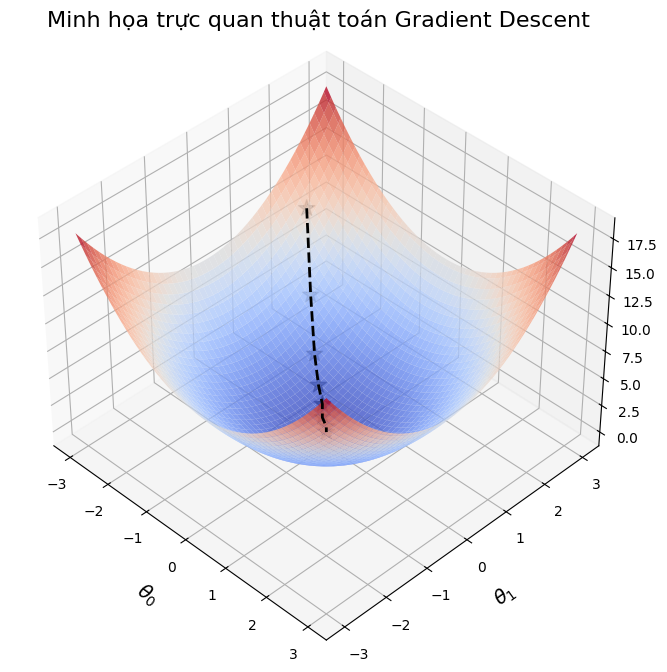

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import os

# 1. Định nghĩa hàm Loss (Hàm lồi - Convex) để minh họa
# Hàm dạng cái bát: J = theta0^2 + theta1^2
def loss_function(theta0, theta1):
    return theta0**2 + theta1**2

# 2. Tạo dữ liệu cho bề mặt 3D
theta0_range = np.linspace(-3, 3, 100)
theta1_range = np.linspace(-3, 3, 100)
Theta0, Theta1 = np.meshgrid(theta0_range, theta1_range)
J = loss_function(Theta0, Theta1)

# 3. Mô phỏng các bước nhảy Gradient Descent (Tự tạo dữ liệu giả lập đường đi)
# Bắt đầu từ điểm (-2.5, 2.0) và đi dần về (0,0)
path_theta0 = [-2.5, -1.8, -1.2, -0.8, -0.5, -0.3, -0.1, 0]
path_theta1 = [ 2.0,  1.4,  0.9,  0.6,  0.4,  0.2,  0.1, 0]
path_J = [loss_function(t0, t1) for t0, t1 in zip(path_theta0, path_theta1)]

# 4. Vẽ biểu đồ
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Vẽ bề mặt (Surface)
surf = ax.plot_surface(Theta0, Theta1, J, cmap='coolwarm', alpha=0.8, antialiased=True)

# Vẽ đường đi của Gradient Descent
# Đường nối
ax.plot(path_theta0, path_theta1, path_J, color='black', linewidth=2, linestyle='--', zorder=10)
# Các điểm (Dấu sao)
ax.scatter(path_theta0, path_theta1, path_J, color='black', marker='*', s=150, zorder=10, label='GD Steps')

# Trang trí biểu đồ
ax.set_xlabel(r'$\theta_0$', fontsize=14, labelpad=10)
ax.set_ylabel(r'$\theta_1$', fontsize=14, labelpad=10)
ax.set_zlabel(r'$J(\theta)$', fontsize=14, labelpad=10)
ax.set_title('Minh họa trực quan thuật toán Gradient Descent', fontsize=16)
ax.view_init(elev=40, azim=-45) # Góc nhìn đẹp nhất

plt.show()

# 5. Huấn luyện và đánh giá

In [ ]:
# Thiết lập siêu tham số
LEARNING_RATE = 0.1
ITERATIONS_GD = 1000  # GD cần nhiều vòng lặp hơn
ITERATIONS_NEWTON = 20 # Newton chỉ cần rất ít vòng lặp

# --- Huấn luyện bằng Gradient Descent ---
start_time_gd = time.time()
w_gd, loss_gd = gradient_descent(X_train_final, y_train, LEARNING_RATE, ITERATIONS_GD)
end_time_gd = time.time()
time_gd = end_time_gd - start_time_gd
print(f"--- Gradient Descent ---")
print(f"Thời gian huấn luyện: {time_gd:.4f} giây")

# --- Huấn luyện bằng Phương pháp Newton ---
start_time_newton = time.time()
w_newton, loss_newton = newtons_method(X_train_final, y_train, ITERATIONS_NEWTON)
end_time_newton = time.time()
time_newton = end_time_newton - start_time_newton
print(f"\n--- Newton's Method ---")
print(f"Thời gian huấn luyện: {time_newton:.4f} giây")


# --- Đánh giá trên tập kiểm tra ---
def predict(X, w):
    """Dự đoán nhãn (0 hoặc 1) từ trọng số đã học."""
    return sigmoid(X @ w) >= 0.5

def accuracy(y_true, y_pred):
    """Tính toán độ chính xác."""
    return np.mean(y_true == y_pred) * 100

# Độ chính xác của Gradient Descent
y_pred_gd = predict(X_test_final, w_gd)
acc_gd = accuracy(y_test, y_pred_gd)
print(f"\nĐộ chính xác của Gradient Descent trên tập test: {acc_gd:.2f}%")

# Độ chính xác của Phương pháp Newton
y_pred_newton = predict(X_test_final, w_newton)
acc_newton = accuracy(y_test, y_pred_newton)
print(f"Độ chính xác của Newton's Method trên tập test: {acc_newton:.2f}%")

--- Gradient Descent ---
Thời gian huấn luyện: 0.1147 giây
Newton's method converged at iteration 7

--- Newton's Method ---
Thời gian huấn luyện: 0.0120 giây

Độ chính xác của Gradient Descent trên tập test: 85.25%
Độ chính xác của Newton's Method trên tập test: 85.25%


# 6. Trực quan kết quả

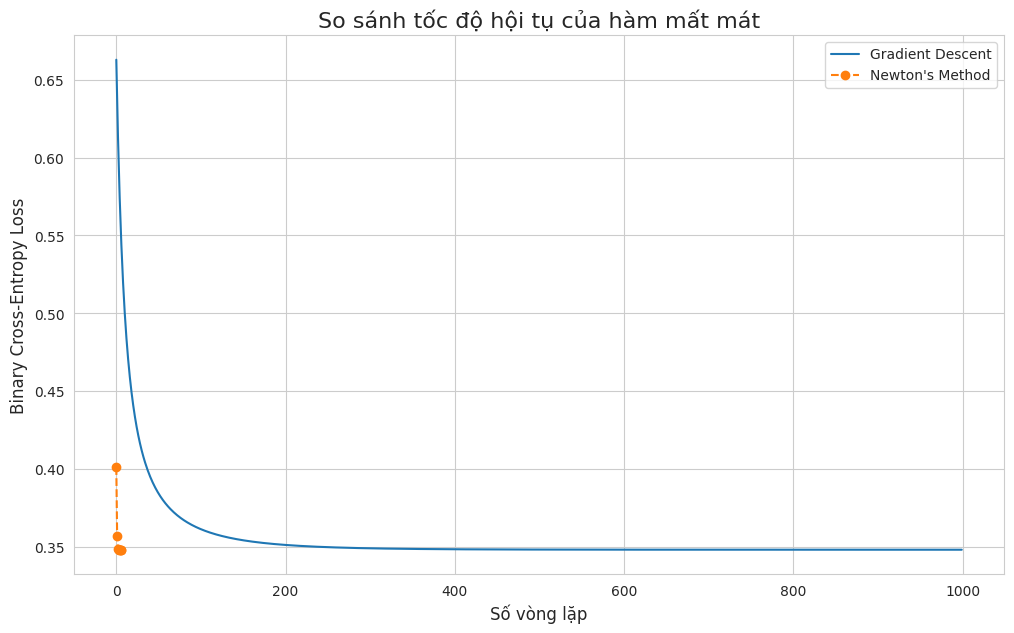

In [ ]:
plt.figure(figsize=(12, 7))
plt.plot(loss_gd, label="Gradient Descent")
# Chỉ vẽ số vòng lặp mà Newton thực sự chạy
plt.plot(np.arange(len(loss_newton)), loss_newton, label="Newton's Method", linestyle='--', marker='o')

plt.title("So sánh tốc độ hội tụ của hàm mất mát", fontsize=16)
plt.xlabel("Số vòng lặp", fontsize=12)
plt.ylabel("Binary Cross-Entropy Loss", fontsize=12)
plt.legend()
plt.grid(True)
plt.show()


--- Bắt đầu Thí nghiệm 2: Khảo sát Learning Rate ---
Đang chạy với learning rate: 0.01
Đang chạy với learning rate: 0.1
Đang chạy với learning rate: 1.0


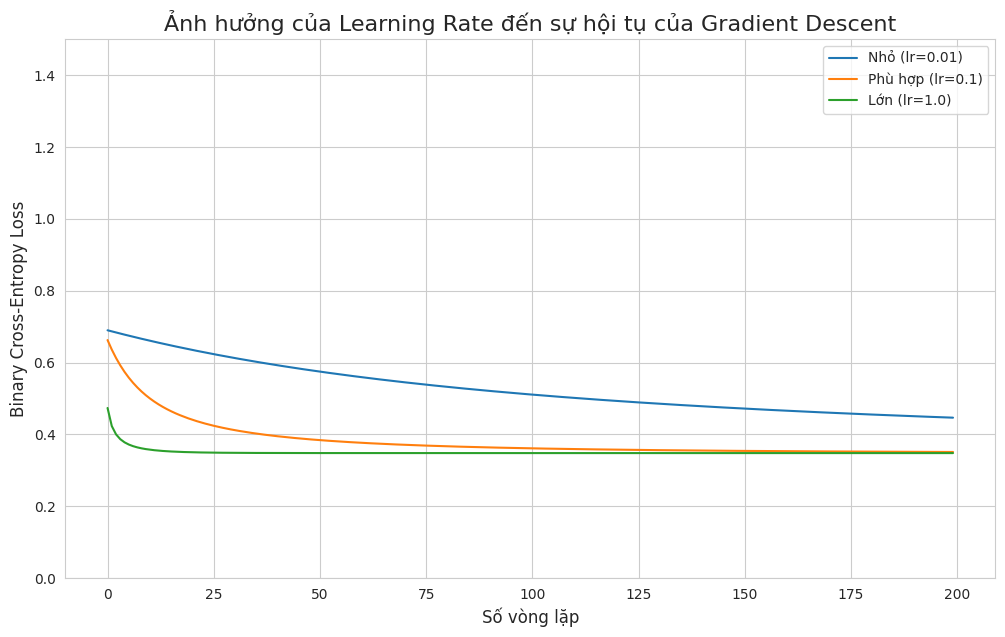

In [ ]:
# ===================================================================
# THÍ NGHIỆM 2: KHẢO SÁT SỰ NHẠY CẢM CỦA GD VỚI LEARNING RATE
# ===================================================================
print("\n--- Bắt đầu Thí nghiệm 2: Khảo sát Learning Rate ---")

# Các giá trị learning rate cần kiểm tra
learning_rates_to_test = {
    "Nhỏ (lr=0.01)": 0.01,
    "Phù hợp (lr=0.1)": 0.1,
    "Lớn (lr=1.0)": 1.0
}

# Lưu trữ lịch sử loss cho mỗi learning rate
loss_histories_lr = {}

# Chạy GD với mỗi learning rate
for name, lr in learning_rates_to_test.items():
    print(f"Đang chạy với learning rate: {lr}")
    # Sử dụng hàm gradient_descent_method đã định nghĩa ở trên
    _, loss_history = gradient_descent_method(X_train_final, y_train, lr, 200) # Chỉ cần 200 vòng lặp để thấy sự khác biệt
    loss_histories_lr[name] = loss_history

# Trực quan hóa kết quả
plt.figure(figsize=(12, 7))
for name, loss_history in loss_histories_lr.items():
    plt.plot(loss_history, label=name)

plt.title("Ảnh hưởng của Learning Rate đến sự hội tụ của Gradient Descent", fontsize=16)
plt.xlabel("Số vòng lặp", fontsize=12)
plt.ylabel("Binary Cross-Entropy Loss", fontsize=12)
plt.legend()
plt.ylim(0, 1.5) # Giới hạn trục y để đồ thị dễ đọc hơn khi lr lớn
plt.grid(True)
plt.savefig("learning_rate_comparison.png") # Lưu hình ảnh
plt.show()


--- Bắt đầu Thí nghiệm 3: Khảo sát Chuẩn hóa Dữ liệu ---
Đang chạy GD trên dữ liệu gốc (chưa chuẩn hóa)...
Đang chạy GD trên dữ liệu đã chuẩn hóa...


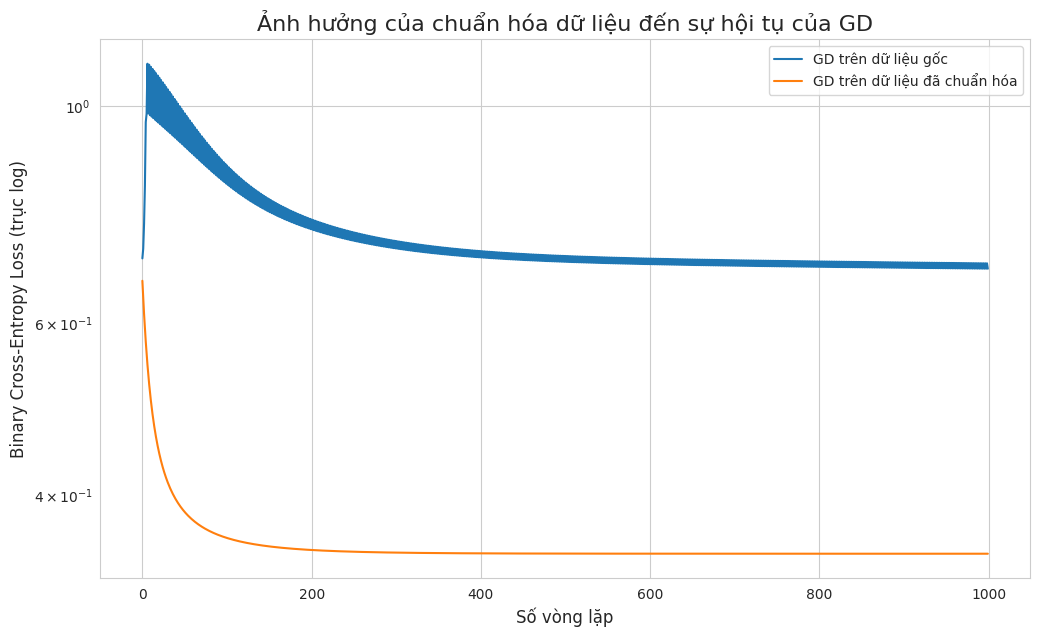

In [ ]:
# ===================================================================
# THÍ NGHIỆM 3: KHẢO SÁT ẢNH HƯỞNG CỦA CHUẨN HÓA DỮ LIỆU
# ===================================================================
print("\n--- Bắt đầu Thí nghiệm 3: Khảo sát Chuẩn hóa Dữ liệu ---")

# Lấy dữ liệu chưa được chuẩn hóa
X_train_unscaled, _, y_train_unscaled, _ = train_test_split(X, y, test_size=0.2, random_state=42)

# Thêm cột bias vào dữ liệu chưa chuẩn hóa
X_train_unscaled_final = np.c_[np.ones(X_train_unscaled.shape[0]), X_train_unscaled.values]
y_train_unscaled = y_train_unscaled.values.reshape(-1, 1)

# Chạy GD trên dữ liệu CHƯA chuẩn hóa
print("Đang chạy GD trên dữ liệu gốc (chưa chuẩn hóa)...")
_, loss_unscaled = gradient_descent_method(X_train_unscaled_final, y_train_unscaled, 0.0001, 1000) # Cần lr rất nhỏ

# Chạy GD trên dữ liệu ĐÃ chuẩn hóa (lấy lại từ thí nghiệm 1)
print("Đang chạy GD trên dữ liệu đã chuẩn hóa...")
_, loss_scaled = gradient_descent_method(X_train_final, y_train, 0.1, 1000)

# Trực quan hóa kết quả
plt.figure(figsize=(12, 7))
plt.plot(loss_unscaled, label="GD trên dữ liệu gốc")
plt.plot(loss_scaled, label="GD trên dữ liệu đã chuẩn hóa")
plt.title("Ảnh hưởng của chuẩn hóa dữ liệu đến sự hội tụ của GD", fontsize=16)
plt.xlabel("Số vòng lặp", fontsize=12)
plt.ylabel("Binary Cross-Entropy Loss (trục log)", fontsize=12)
plt.yscale('log') # Sử dụng trục log để thấy rõ sự khác biệt lớn
plt.legend()
plt.grid(True)
plt.savefig("scaling_comparison.png") # Lưu hình ảnh
plt.show()